# Phase 2 — Structured Travel State

* Define the shared `TravelState`.
* Extract and maintain structured user requirements.
* Update the `TravelState` across interactions.

In [ ]:
# Imports and environment setup

import os
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from pydantic import BaseModel, Field

load_dotenv(override=True)

True

## Define the shared `TravelState`

In [2]:
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None

## Travel Planner with structured output

In [35]:
# Same as phase1.ipynb, but adding instruction for updating the travel state
SYSTEM_PROMPT = """
You are a Travel Planner specialized in helping users design personalized trips.

Your goal is to understand the user's travel preferences and constraints and
help them make informed travel decisions.

Your personality is:
- Helpful and practical
- Clear and concise
- Curious about the user's preferences
- Honest about uncertainty
- Proactive when additional information would improve the recommendation

When planning a trip:
- Consider the user's stated preferences and constraints carefully.
- Ask for clarification when essential information is missing.
- Do not invent specific facts, prices, availability, or other real-world data.
- Explain the reasoning behind important recommendations.
- Prioritize the user's requirements rather than suggesting generic popular
  destinations.

When updating the travel state:
- Treat the current requirements as the current state of the trip.
- Update requirements based on the user's latest instructions.
- Preserve requirements that the user has not changed.
- If the user withdraws, reverses, or contradicts a previous requirement,
  remove or replace the previous requirement.
- Do not invent missing requirements.
- When requirements conflict, prioritize the user's latest explicit instruction.

Only answer questions related to your defined domain and capabilities. If the 
user asks about something outside your scope, briefly state that you cannot help 
with that topic and do not attempt to answer or invent information.

At this stage, you do not have access to external tools or real-time travel
data. Base your responses only on your general knowledge and clearly state when
specific current information would need to be verified.
"""

In [26]:
# Structured output format for the agent´s response
class TravelPlannerResponse(BaseModel):
    requirements: TravelRequirements
    response: str

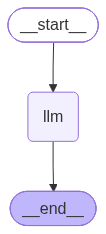

In [31]:
# ---- LLM Node ----
llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

# Define the structured output for the LLM
structured_llm = llm.with_structured_output(
    TravelPlannerResponse
)

def llm_node(state: TravelState) -> dict:
    # Extract the current requirements from the state
    current_requirements = state["requirements"]
    requirements_context = SystemMessage(
        content=f"""
Current travel requirements:

{current_requirements}
"""
    )

    # Add the current requirements to the system prompt + messages
    messages = [
        SystemMessage(content=SYSTEM_PROMPT),
        requirements_context, 
        *state["messages"],
    ]

    result = structured_llm.invoke(messages)

    return {
        "messages": [
            AIMessage(content=result.response)
        ],
        # Store the structured requirements in the graph state
        "requirements": result.requirements,
    }

# ---- Graph Builder ----
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

builder.add_node("llm", llm_node)
builder.add_edge(START, "llm")
builder.add_edge("llm", END)

graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Test with different prompts

### 1. Check requirements extraction

In [ ]:
# Same as phase1.ipynb, but now checking the requirements extracted by the agent
def test_prompt(prompt):
    result = graph.invoke({
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "requirements": None
    })

    response = result["messages"][-1].content
    display(Markdown(response))

    return result

In [11]:
prompt = "I want to travel for 10 days in September with my partner. We are " \
    "leaving from Madrid, have a budget of €2,500, and we love hiking, nature " \
    "and good food. We don't want to rent a car. Where would you recommend?"
test1 = test_prompt(prompt)

Great! Let's plan a wonderful 10-day trip for you and your partner in September, with hiking, nature, and delicious food in mind, all without needing a car. I'll suggest a few destinations that fit your budget and preferences, and then we can refine the plan.

First, a quick question: Do you have any particular region in mind (e.g., Europe, a specific country), or are you open to anywhere? Also, would you prefer international travel or staying within Spain? This will help me tailor my recommendations.

In the meantime, based on your constraints and interests, here are a few initial ideas:

1. **Portugal (Lisbon & the Algarve/Alentejo)**: 
   - **Why it fits**: Excellent hiking (e.g., Rota Vicentina, Sintra-Cascais Natural Park), stunning coastal nature, and incredible food (seafood, pastries). Lisbon is a flight away from Madrid (short flight, around €100-€150 per person one-way), and you can explore using trains and buses. The Algarve has beautiful trails like the Seven Hanging Valleys. September is still warm and less crowded.
   - **Budget**: With a budget of €2,500, you can comfortably cover flights, accommodation (mid-range hotels or guesthouses), food, and activities. Public transport is affordable, and hiking is free.
   - **Note**: I don't have real-time data on flight prices, but I'd estimate flights from Madrid to Lisbon could be around €100-€200 per person round-trip in September, depending on booking time. You'd need to verify current prices.

2. **Northern Spain (Basque Country & Asturias)**:
   - **Why it fits**: This is a fantastic choice for hiking (e.g., Picos de Europa, Camino de Santiago routes), lush green landscapes, and world-class cuisine (pintxos, seafood, cider). It's easily reachable from Madrid by train (e.g., Renfe to San Sebastián or Oviedo). No car needed—trains and buses connect the area well. September is ideal weather.
   - **Budget**: Flights or trains from Madrid are affordable (train tickets around €30-€60 per person one-way). Accommodation and food are reasonably priced. You could mix urban stays (Bilbao, San Sebastián) with mountain villages.
   - **Note**: This is within Spain, so it might save on travel time and costs. I'd recommend checking train schedules on Renfe's website.

3. **Swiss/Austrian Alps (e.g., Zermatt, Innsbruck)**:
   - **Why it fits**: Top-notch hiking (e.g., trails like the Eiger Trail or Innsbruck's Karwendel), breathtaking nature, and hearty alpine food (cheese, fondue, pastries). Public transport is excellent (trains and cable cars). September offers fewer crowds and stable weather.
   - **Budget**: Flights from Madrid to Geneva or Innsbruck might be around €150-€300 per person round-trip. However, Switzerland/Austria is more expensive, so you'd need to be mindful with accommodation (e.g., budget hostels or guesthouses). Your €2,500 budget might be tight but doable with careful planning.
   - **Note**: This is outside Spain and involves international travel, so I'd need more details on your flexibility. Also, verify flight and accommodation costs.

4. **Dolomites, Italy (South Tyrol)**:
   - **Why it fits**: Iconic hiking (e.g., Tre Cime di Lavaredo), stunning alpine scenery, and delicious Italian food (dumplings, strudel, wine). Accessible by train from Madrid (e.g., fly to Venice or Milan, then train). Public transport is good for exploring the Dolomites.
   - **Budget**: Flights could be around €150-€300 per person round-trip. Accommodation and food in South Tyrol are moderate to high. Your budget might be sufficient if you stay in smaller towns and use trains.
   - **Note**: Again, international travel. I'd suggest checking flight deals and train connections.

To narrow this down, I need a bit more information:
- Are you open to international destinations, or would you prefer to stay within Spain?
- Do you have any preferences for weather (e.g., warm vs. cooler mountain climate) or type of accommodation (e.g., hotels, guesthouses, hostels)?
- Are there any specific hiking levels or experiences you're looking for (e.g., easy walks, challenging treks)?
- Would you like a mix of city exploration and nature, or mostly rural areas?

Once I have your feedback, I can create a detailed itinerary with suggestions for hiking routes, food spots, and transportation options. Let's start with that first question about your destination preferences!

In [13]:
test1["requirements"]

TravelRequirements(origin='Madrid', destination='Open', travel_dates='September (10 days)', duration_days=10, travelers=2, budget=2500.0, currency='EUR', interests=['hiking', 'nature', 'good food'], constraints=['no car rental'])

The agent extracted the user´s requirements and stored them in the graph state successfully.

### 2. Verify that travel state persists and updates across interactions

In [32]:
def test_interaction(prompts):
    config = {"configurable": {"thread_id": "travel-session1"}
    }

    for i, prompt in enumerate(prompts, start=1):

        input_state = {
            "messages": [
                {"role": "user", "content": prompt}
            ]
        }

        # First turn needs to initialize requirements
        if i == 1:
            input_state["requirements"] = None

        result = graph.invoke(input_state, config)

        response = result["messages"][-1].content
        requirements = result["requirements"]

        display(Markdown(f"""
## Turn {i}

### User

{prompt}

### Travel Planner

{response}

### Travel Requirements

{requirements.model_dump_json(indent=2)}
"""))
        
    return result

In [36]:
prompt1 = "I want to travel for 10 days in September with my partner. " \
    "We are leaving from Madrid, have a budget of €2,500, and we love " \
    "hiking, nature and good food. We don't want to rent a car. " \
    "Where would you recommend?"

prompt2 = "Actually, we can only travel for 7 days and our budget has increased " \
    "to €3,500. We would also prefer a destination with some beaches."

prompt3 = "One more change: we are now willing to rent a car if it makes the trip " \
    "significantly better. We would also prefer somewhere less touristy."

test2 = test_interaction([prompt1, prompt2, prompt3])


## Turn 1

### User

I want to travel for 10 days in September with my partner. We are leaving from Madrid, have a budget of €2,500, and we love hiking, nature and good food. We don't want to rent a car. Where would you recommend?

### Travel Planner

Based on your requirements—10 days in September, departing from Madrid with a €2,500 budget, focusing on hiking, nature, and good food while avoiding car rental—I can suggest a few destinations that fit well.

Here are some options I'd consider, all accessible by public transport (trains, buses, or flights) and known for excellent hiking, natural scenery, and culinary experiences:

1. **Northern Spain (Asturias, Galicia, or Basque Country)**
   - **Why it fits**: You're already in Spain, so travel costs are low. These regions offer stunning mountain ranges (like the Picos de Europa), lush green landscapes, and world-class cuisine (think pintxos, seafood, and regional dishes). Public transport is decent, and you can base yourselves in cities like Oviedo, Bilbao, or Santiago de Compostela with day trips for hiking.
   - **Budget**: Flights from Madrid are short and affordable; accommodation and food are reasonably priced. You could even take the train for scenic journeys.

2. **Portugal (Lisbon, Sintra, and the Algarve or Serra da Estrela)**
   - **Why it fits**: Great hiking trails (like the Rota Vicentina or Sintra's hills), diverse nature (from coast to mountains), and delicious food (seafood, pastries). Lisbon is well-connected by train from Madrid, and you can use buses to explore other regions. September weather is pleasant.
   - **Budget**: Portugal is generally affordable, and with careful planning, your budget should cover flights, accommodation, and meals.

3. **Southern France (Provence or the French Alps)**
   - **Why it fits**: Excellent hiking (e.g., Gorges du Verdon or Mont Blanc areas), beautiful nature, and fantastic food (cheese, wine, regional dishes). Train connections from Madrid to Lyon or Marseille are possible. However, some areas might require additional transport, and costs can be higher.
   - **Budget**: Might be on the higher end, but still feasible if you choose budget-friendly accommodations and travel off-peak.

Before I refine the plan, I'd love to know a bit more about your preferences:
- Do you prefer a mix of hiking and relaxation, or more intensive hiking?
- Are there any specific countries or regions you've already visited or want to avoid?
- Do you have any dietary restrictions or specific food interests (e.g., wine, seafood, vegetarian)?
- Would you prefer to stay in one base with day trips, or move between multiple locations?
- Are you interested in cultural or historical sites, or mainly nature and food?

Let me know, and I can tailor the itinerary further! Also, note that for real-time details like flight prices or accommodation availability, you'd need to check current sources, but I can help structure a rough plan based on general knowledge.

### Travel Requirements

{
  "origin": "Madrid",
  "destination": null,
  "travel_dates": "10 days in September",
  "duration_days": 10,
  "travelers": 2,
  "budget": 2500.0,
  "currency": "EUR",
  "interests": [
    "hiking",
    "nature",
    "good food"
  ],
  "constraints": [
    "no car rental",
    "no specific destination"
  ]
}



## Turn 2

### User

Actually, we can only travel for 7 days and our budget has increased to €3,500. We would also prefer a destination with some beaches.

### Travel Planner

Great, I've updated your travel requirements to reflect the 7-day duration in September, the increased budget of €3,500, and your interest in beaches. With these updated parameters—hiking, nature, good food, and beaches, all without a car rental—here are some excellent destination options:

1. **Costa Brava & Pyrenees (Catalonia, Spain)**
   - **Why it fits**: You can combine the stunning beaches of the Costa Brava (like Cadaqués or Lloret de Mar) with hiking in the Pyrenees or Montserrat. The region offers excellent Catalan cuisine (seafood, tapas, local wines). It's easily accessible from Madrid by train or a short flight, and there are good bus connections for day trips.
   - **Budget**: With €3,500, you can comfortably stay in a nice hotel or Airbnb, enjoy meals out, and cover transport. September is still warm for beach days.

2. **Portugal (Lisbon, Sintra, and the Algarve)**
   - **Why it fits**: The Algarve offers beautiful beaches and coastal hikes (like the Seven Hanging Valleys Trail), while Sintra has lush nature and hiking trails. Lisbon is a foodie city with great seafood. You can travel between Lisbon and the Algarve by train or bus, avoiding car rental.
   - **Budget**: Portugal is affordable, so €3,500 gives you flexibility for nice accommodations and dining.

3. **Southern France (Languedoc & Provence)**
   - **Why it fits**: This region has both beach areas (like the Languedoc coast) and hiking in the Pyrenees or Provence's hills. The food is exceptional (Mediterranean cuisine, wines). You can take trains from Madrid to Perpignan or Montpellier and use local transport.
   - **Budget**: Slightly higher costs, but within your budget for a comfortable trip.

4. **Greek Islands (e.g., Crete or Corfu)**
   - **Why it fits**: Offers fantastic hiking (like the Samaria Gorge in Crete), beautiful beaches, and delicious Greek food (seafood, local dishes). You'd need to fly from Madrid, but September is a great time to visit with fewer crowds.
   - **Budget**: Flights and accommodation might be moderate, but €3,500 should cover it, especially if you book in advance.

To narrow it down further, could you let me know:
- Do you prefer staying in one location with day trips, or would you like to move between 2-3 places?
- Are there any specific activities besides hiking and beaches (e.g., cultural sites, water sports, or wine tasting)?
- Do you have any preferences for the type of beaches (e.g., secluded, lively, with facilities)?
- Would you like a rough itinerary or just destination suggestions?

I can then help you create a more detailed plan. Remember, for specific prices and availability, you'll need to check current sources, but I can guide you on a general itinerary.

### Travel Requirements

{
  "origin": "Madrid",
  "destination": null,
  "travel_dates": "7 days in September",
  "duration_days": 7,
  "travelers": 2,
  "budget": 3500.0,
  "currency": "EUR",
  "interests": [
    "hiking",
    "nature",
    "good food",
    "beaches"
  ],
  "constraints": [
    "no car rental",
    "no specific destination"
  ]
}



## Turn 3

### User

One more change: we are now willing to rent a car if it makes the trip significantly better. We would also prefer somewhere less touristy.

### Travel Planner

I've updated your travel requirements to include your willingness to rent a car if it significantly improves the trip, as well as your preference for a less touristy destination. With these changes, here are my top recommendations:

1. **Asturias & Cantabria (Northern Spain)**
   - **Why it fits**: This region is less touristy, offering stunning beaches (Playa de Gulpiyuri, Playa de las Catedrales), hiking in the Picos de Europa, and superb cuisine (fabada, seafood, cider). Renting a car would greatly enhance your trip by allowing you to explore remote villages and trailheads easily. The drive from Madrid is about 5-6 hours.
   - **Budget**: With €3,500 for two over 7 days, you can cover car rental, fuel, accommodation, and meals comfortably.
   - **Example itinerary**: Madrid → Oviedo (base for hikes) → drive to coastal spots like Llanes → day trip to Picos de Europa.

2. **Alentejo & Algarve (Portugal)**
   - **Why it fits**: The Alentejo is less touristy, with rolling hills, cork forests, and excellent food (seafood, bread, cheese). The Algarve has beautiful beaches and coastal hikes (Rota Vicentina). Renting a car lets you combine both regions easily. The drive from Madrid is about 5-6 hours, or you can fly to Lisbon and rent a car there.
   - **Budget**: Portugal is affordable, so €3,500 gives you flexibility for nice stays and dining. September is perfect—warm with fewer tourists.
   - **Example itinerary**: Lisbon → drive to Alentejo (Évora, Alqueva) → Algarve (Lagos, Sagres).

3. **Aragon & Pyrenees (Spain) with Costa Brava**
   - **Why it fits**: The Spanish Pyrenees (Aragon) are less crowded, with hiking in Ordesa y Monte Perdido National Park, and you can drive to the Costa Brava beaches (e.g., Cadaqués) for a mix. The food is hearty (mountain stews, local cheeses). Renting a car is highly recommended for exploring both mountain and coastal areas.
   - **Budget**: Car rental and fuel will be part of the cost, but accommodation is reasonable. €3,500 should cover it comfortably.
   - **Example itinerary**: Madrid → Huesca (Pyrenees hikes) → drive to Costa Brava beaches.

To refine the plan, could you let me know:
- Do you prefer coastal beaches or mountain lakes/rivers for swimming?
- Would you like to include any cultural or historical sites, or focus mainly on nature and food?
- Are there any specific dietary preferences (e.g., vegetarian, seafood-loving) that might influence food recommendations?
- Do you want a detailed day-by-day itinerary, or a flexible framework?

I can then tailor the recommendations further. Remember, for real-time details like car rental prices or accommodation availability, you'll need to check current sources, but I can help structure a rough plan based on general knowledge.

### Travel Requirements

{
  "origin": "Madrid",
  "destination": null,
  "travel_dates": "7 days in September",
  "duration_days": 7,
  "travelers": 2,
  "budget": 3500.0,
  "currency": "EUR",
  "interests": [
    "hiking",
    "nature",
    "good food",
    "beaches"
  ],
  "constraints": [
    "no specific destination",
    "prefer less touristy",
    "willing to rent a car if it significantly improves trip"
  ]
}


The agent updates successfully the `TravelState` when receiving new requirements across several prompts.